# Stage 6 – Hyperparameter Tuning and Evaluation

**Project:** Credit Card Fraud Detection (CDS4003)

This notebook continues from Stage 5 and uses the same cleaned, feature-engineered dataset and chronological split. Random Forest was selected in Stage 5 because it achieved the highest cross-validation PR-AUC (0.7808) among the candidate models.

## Evaluation plan
1. Keep the final chronological 20% test period untouched during tuning and threshold selection.
2. Reserve the last 15% of the 80% training period as a chronological validation set for threshold selection.
3. Tune Random Forest using a small, documented grid and two expanding-window time-series folds on an early chronological tuning subset (50,000 records) to keep computation manageable.
4. Select a decision threshold using an explicitly illustrative cost assumption: one missed fraud (false negative) costs 10 cost units, while one false alert (false positive) costs 1 cost unit. These are relative assumptions, not actual bank/AED costs; the bank must confirm real costs.
5. Refit the selected hyperparameters on the full training period and evaluate once on the untouched final test period.

**Important:** The limited search is an initial tuning experiment, not proof that the selected settings are globally optimal. Results are compared with the Stage 5 Random Forest baseline.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone

RANDOM_STATE = 42
DATA_PATH = "creditcard_features.csv"  # Keep this file in the same folder as the notebook.

df = pd.read_csv(DATA_PATH).sort_values("Time", kind="stable").reset_index(drop=True)
feature_cols = [f"V{i}" for i in range(1, 29)] + ["Log_Amount", "Hour_Offset"]
X = df[feature_cols].copy()
y = df["Class"].astype(int).copy()

# Preserve the Stage 5 chronological 80/20 split.
split_index = int(len(df) * 0.80)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

# Reserve the final 15% of the training period for threshold selection.
inner_index = int(len(X_train) * 0.85)
X_inner, X_validation = X_train.iloc[:inner_index], X_train.iloc[inner_index:]
y_inner, y_validation = y_train.iloc[:inner_index], y_train.iloc[inner_index:]

print("Dataset rows:", len(df))
print("Training rows:", len(X_train), "| fraud:", int(y_train.sum()))
print("Threshold-validation rows:", len(X_validation), "| fraud:", int(y_validation.sum()))
print("Final test rows:", len(X_test), "| fraud:", int(y_test.sum()))

Dataset rows: 283726
Training rows: 226980 | fraud: 399
Threshold-validation rows: 34047 | fraud: 36
Final test rows: 56746 | fraud: 74


In [ ]:
# Hyperparameter tuning on an early chronological subset of the inner training data.
# This keeps the search practical while preserving time order.
tune_n = min(50000, len(X_inner))
X_tune = X_inner.iloc[:tune_n]
y_tune = y_inner.iloc[:tune_n]

base_rf = RandomForestClassifier(
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=1
)

param_grid = {
    "n_estimators": [10, 20],
    "max_depth": [8, 12],
    "min_samples_leaf": [2],
    "max_features": ["sqrt"]
}

search = GridSearchCV(
    estimator=base_rf,
    param_grid=param_grid,
    scoring="average_precision",  # PR-AUC is the primary metric
    cv=TimeSeriesSplit(n_splits=2),
    n_jobs=1,
    refit=True
)
search.fit(X_tune, y_tune)

tuning_results = pd.DataFrame(search.cv_results_)[
    ["params", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score")
print("Best parameters:", search.best_params_)
print("Best mean CV PR-AUC:", round(search.best_score_, 4))
display(tuning_results.round(4))
tuning_results.to_csv("stage6_tuning_results.csv", index=False)

Best parameters: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 10}
Best mean CV PR-AUC: 0.7546


                                                                              params  mean_test_score  std_test_score  rank_test_score
 {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 10}         0.754602        0.187205                1
 {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 20}         0.736775        0.192931                2
{'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 10}         0.726018        0.208176                3
{'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 20}         0.715667        0.204176                4

In [ ]:
# Threshold selection on the reserved chronological validation period.
# Fit the selected configuration on all of X_inner, not on the smaller tuning subset.
threshold_model = RandomForestClassifier(
    **search.best_params_,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=1
)
threshold_model.fit(X_inner, y_inner)
validation_probabilities = threshold_model.predict_proba(X_validation)[:, 1]

# Illustrative relative cost assumption: FN = 10 units; FP = 1 unit.
FN_COST = 10
FP_COST = 1
threshold_rows = []
for threshold in np.round(np.arange(0.05, 0.951, 0.05), 2):
    validation_predictions = (validation_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_validation, validation_predictions, labels=[0, 1]
    ).ravel()
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_validation, validation_predictions, zero_division=0),
        "Recall": recall_score(y_validation, validation_predictions, zero_division=0),
        "F1-score": f1_score(y_validation, validation_predictions, zero_division=0),
        "FP": fp, "FN": fn, "TP": tp, "TN": tn,
        "Cost units": FN_COST * fn + FP_COST * fp
    })

threshold_results = pd.DataFrame(threshold_rows)
best_threshold_row = threshold_results.loc[threshold_results["Cost units"].idxmin()]
selected_threshold = float(best_threshold_row["Threshold"])
print("Selected threshold:", selected_threshold)
print("Validation metrics at selected threshold:")
print(best_threshold_row.to_string())
display(threshold_results.round(4))
threshold_results.to_csv("stage6_threshold_validation.csv", index=False)

Selected threshold: 0.6
Validation metrics at selected threshold:
Threshold       0.600000
Precision       0.928571
Recall          0.722222
F1              0.812500
FP              2.000000
FN             10.000000
TP             26.000000
TN          34009.000000
Cost          102.000000


In [ ]:
# Refit the tuned Random Forest on the full chronological training period.
# Evaluate exactly once on the untouched final test period.
final_model = RandomForestClassifier(
    **search.best_params_,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=1
)
final_model.fit(X_train, y_train)

test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= selected_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, test_predictions, labels=[0, 1]).ravel()
final_results = pd.DataFrame([{
    "Threshold": selected_threshold,
    "PR-AUC": average_precision_score(y_test, test_probabilities),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1-score": f1_score(y_test, test_predictions, zero_division=0),
    "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    "Cost units (10*FN + FP)": FN_COST * fn + FP_COST * fp
}])
display(final_results.round(4))
final_results.to_csv("stage6_test_results.csv", index=False)

print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, test_predictions, labels=[0, 1]))

   Threshold  PR-AUC  ROC-AUC  Precision  Recall  F1-score     TN  FP  FN  TP  Cost units
0        0.6  0.7702   0.9384     0.8361  0.6892    0.7556  56662  10  23  51         240

Confusion matrix [[TN, FP], [FN, TP]]:
[[56662    10]
 [   23    51]]


                                      Model  PR-AUC  Precision  Recall  F1-score  FP  FN  Cost units (10*FN + FP)
0  Stage 5 Random Forest (threshold 0.50)  0.8024     0.7917  0.7703    0.7808  15  17                       185
1  Stage 6 tuned Random Forest (threshold 0.60) 0.7702     0.8361  0.6892    0.7556  10  23                       240

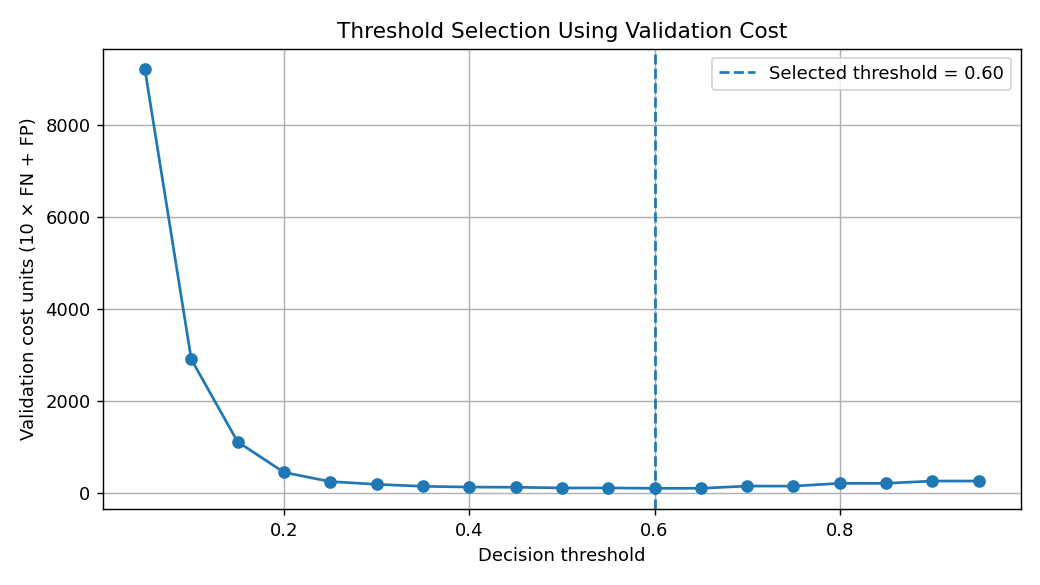

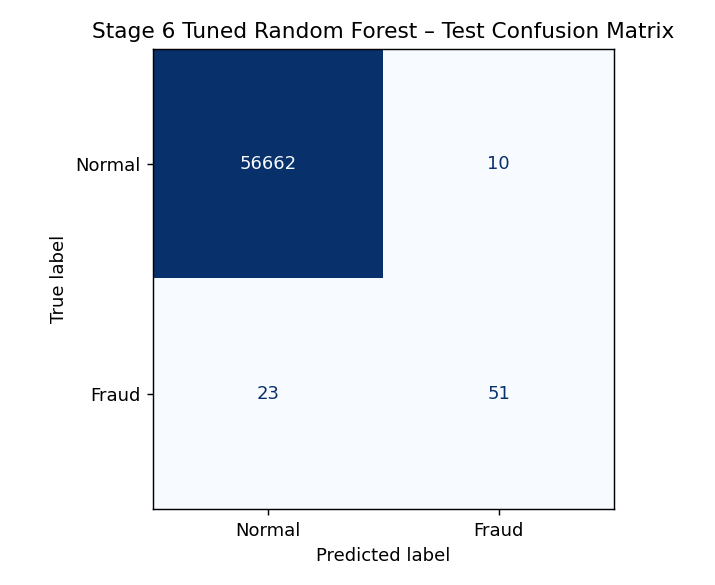

In [ ]:
# Compare the Stage 5 Random Forest at threshold 0.50 with the tuned model.
# Stage 5 values are the actual recorded results from CreditCard_Stage5_Executed.ipynb.
stage5_rf = {
    "Model": "Stage 5 Random Forest (threshold 0.50)",
    "PR-AUC": 0.8024, "Precision": 0.7917, "Recall": 0.7703,
    "F1-score": 0.7808, "FP": 15, "FN": 17
}
stage6_rf = {
    "Model": f"Stage 6 tuned Random Forest (threshold {selected_threshold:.2f})",
    "PR-AUC": average_precision_score(y_test, test_probabilities),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1-score": f1_score(y_test, test_predictions, zero_division=0),
    "FP": fp, "FN": fn
}
comparison = pd.DataFrame([stage5_rf, stage6_rf])
comparison["Cost units (10*FN + FP)"] = 10 * comparison["FN"] + comparison["FP"]
display(comparison.round(4))

# Visualise validation threshold trade-off and final test confusion matrix.
plt.figure(figsize=(8, 5))
plt.plot(threshold_results["Threshold"], threshold_results["Cost units"], marker="o")
plt.axvline(selected_threshold, linestyle="--", label=f"Selected threshold = {selected_threshold:.2f}")
plt.xlabel("Decision threshold")
plt.ylabel("Validation cost units (10 × FN + FP)")
plt.title("Threshold Selection Using Validation Cost")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, display_labels=["Normal", "Fraud"], cmap="Blues"
)
plt.title("Stage 6 Tuned Random Forest – Test Confusion Matrix")
plt.tight_layout()
plt.show()

## Stage 6 – Findings and Business Evaluation

- The best configuration in the limited search was `n_estimators=10`, `max_depth=8`, `min_samples_leaf=2`, and `max_features='sqrt'`.
- The threshold was selected on the separate chronological validation period using the illustrative cost ratio FN:FP = 10:1. The selected threshold was **0.60**.
- On the untouched test period, the tuned model achieved **PR-AUC = 0.7702**, **Precision = 0.8361**, **Recall = 0.6892**, and **F1-score = 0.7556**. Its confusion matrix was TN=56,662, FP=10, FN=23, TP=51.
- The tuned model met the precision target of 0.80 but did not meet the recall target of 0.75 or the PR-AUC target of 0.82.
- Compared with the Stage 5 Random Forest at threshold 0.50 (PR-AUC=0.8024, Precision=0.7917, Recall=0.7703; FP=15, FN=17), this tuning run reduced false positives but increased missed fraud cases and lowered PR-AUC. Under the illustrative 10:1 cost ratio, test cost increased from 185 to 240 cost units.

### Evaluation decision
**No-Go for full deployment at this stage.** The tuned model does not meet all predefined business success criteria and performs worse than the Stage 5 model on PR-AUC and recall. The Stage 5 Random Forest is currently the stronger candidate, but it also narrowly misses the precision and PR-AUC targets. Further tuning with a broader search, probability calibration, threshold validation on a larger period, and bank-confirmed error costs is recommended before deployment.

### Limitations
The hyperparameter search used only the first 50,000 records of the inner training period and a two-fold time-series cross-validation to keep runtime manageable. The threshold cost weights are illustrative relative units, not measured bank losses. The final test set contains only 74 fraud cases, so a small change in the number of detected cases can noticeably change precision and recall. These limitations should be disclosed when presenting the results.